In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Hands-On Data Lab Started!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Hands-On Data Lab Started!
Pandas version: 3.1.0
NumPy version: 2.4.2


In [2]:
data = {
    "Product": ["Laptop", "Phone", "Tablet", "Laptop", "Phone", "Tablet"],
    "Quantity": [2, 5, 3, 1, 4, 2],
    "Price": [50000, 15000, 20000, 50000, 15000, 20000],
    "City": ["Hyderabad", "Vizag", "Vijayawada",
             "Vizag", "Hyderabad", "Vijayawada"]
}

df = pd.DataFrame(data)

df["Revenue"] = df["Quantity"] * df["Price"]

display(df)

,Product,Quantity,Price,City,Revenue
0,Laptop,2,50000,Hyderabad,100000
1,Phone,5,15000,Vizag,75000
2,Tablet,3,20000,Vijayawada,60000
3,Laptop,1,50000,Vizag,50000
4,Phone,4,15000,Hyderabad,60000
5,Tablet,2,20000,Vijayawada,40000


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check dataset information
print("Dataset shape:", df.shape)

# Display basic statistics
display(df.describe())

Missing values:
Product     0
Quantity    0
Price       0
City        0
Revenue     0
dtype: int64
Duplicate rows: 0
Dataset shape: (6, 5)


,Quantity,Price,Revenue
count,6.000000,6.000000,6.000000
mean,2.833333,28333.333333,64166.666667
std,1.471960,16931.233466,21075.261960
min,1.000000,15000.000000,40000.000000
25%,2.000000,16250.000000,52500.000000
50%,2.500000,20000.000000,60000.000000
75%,3.750000,42500.000000,71250.000000
max,5.000000,50000.000000,100000.000000


In [5]:
product_sales = df.groupby("Product")["Revenue"].sum()

print("Product-wise Revenue:")
display(product_sales)

print("Total Revenue:", df["Revenue"].sum())
print("Total Units Sold:", df["Quantity"].sum())

Product-wise Revenue:


Product
Laptop    150000
Phone     135000
Tablet    100000
Name: Revenue, dtype: int64

Total Revenue: 385000
Total Units Sold: 17


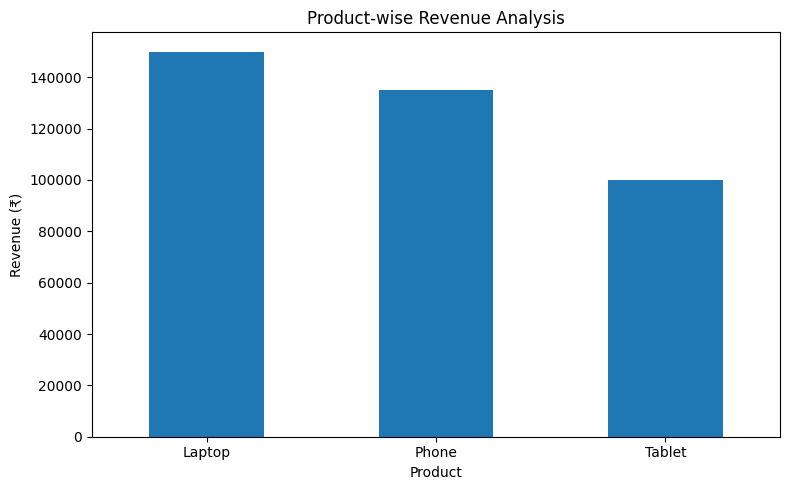

In [6]:
plt.figure(figsize=(8, 5))

product_sales.plot(kind="bar")

plt.title("Product-wise Revenue Analysis")
plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
city_sales = df.groupby("City")["Revenue"].sum().sort_values(ascending=False)

print("City-wise Revenue:")
display(city_sales)

print("Highest Revenue City:", city_sales.idxmax())
print("Lowest Revenue City:", city_sales.idxmin())

City-wise Revenue:


City
Hyderabad     160000
Vizag         125000
Vijayawada    100000
Name: Revenue, dtype: int64

Highest Revenue City: Hyderabad
Lowest Revenue City: Vijayawada


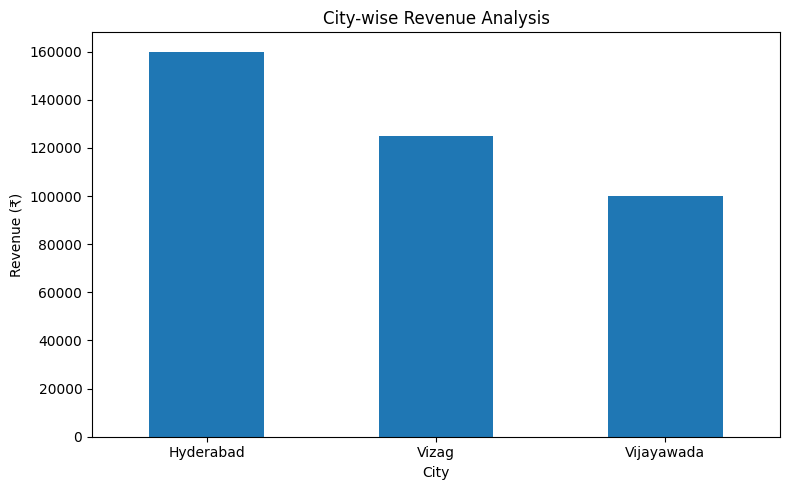

In [8]:
plt.figure(figsize=(8, 5))

city_sales.plot(kind="bar")

plt.title("City-wise Revenue Analysis")
plt.xlabel("City")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

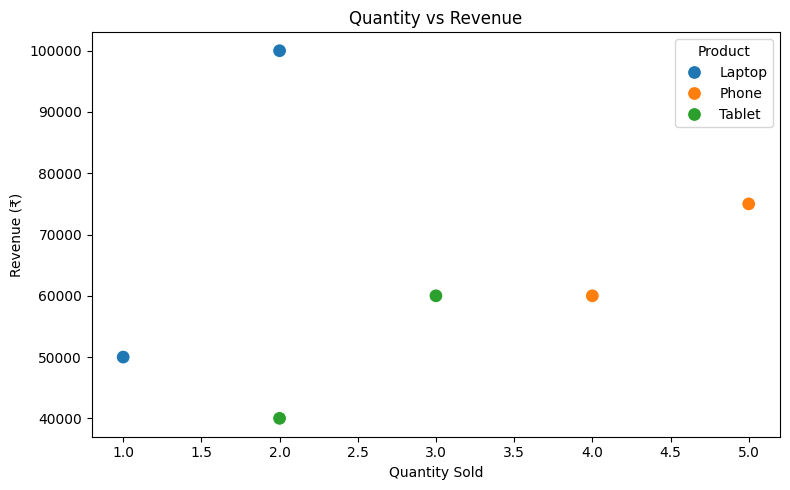

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Revenue",
    hue="Product",
    s=100
)

plt.title("Quantity vs Revenue")
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()


In [10]:
print("===== FINAL DATA ANALYSIS SUMMARY =====")
print("Total Orders:", len(df))
print("Total Units Sold:", df["Quantity"].sum())
print("Total Revenue: ₹", df["Revenue"].sum())
print("Best Revenue Product:", product_sales.idxmax())
print("Highest Revenue City:", city_sales.idxmax())
print("Average Order Revenue: ₹", round(df["Revenue"].mean(), 2))

===== FINAL DATA ANALYSIS SUMMARY =====
Total Orders: 6
Total Units Sold: 17
Total Revenue: ₹ 385000
Best Revenue Product: Laptop
Highest Revenue City: Hyderabad
Average Order Revenue: ₹ 64166.67


Order_Date
February    150000
January     235000
Name: Revenue, dtype: int64

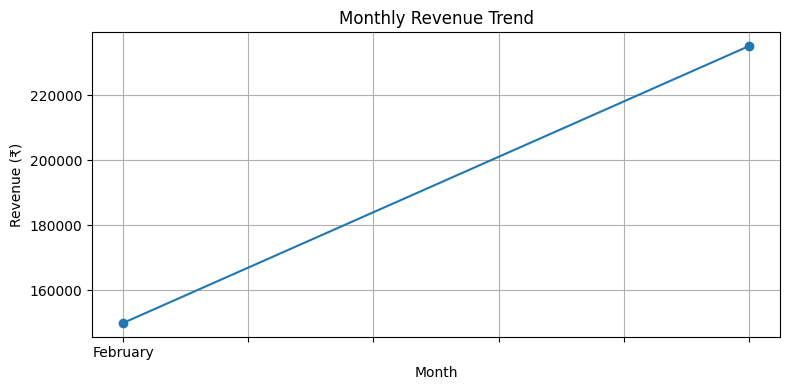

In [11]:
# Create a date column for our sample orders
df["Order_Date"] = pd.to_datetime([
    "2026-01-05",
    "2026-01-07",
    "2026-01-08",
    "2026-02-10",
    "2026-02-12",
    "2026-02-15"
])

# Group revenue by month
monthly_sales = df.groupby(
    df["Order_Date"].dt.strftime("%B")
)["Revenue"].sum()

display(monthly_sales)

monthly_sales.plot(kind="line", marker="o", figsize=(8, 4))
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
highest_order = df.loc[df["Revenue"].idxmax()]

print("Highest Revenue Order:")
display(highest_order)

print("Revenue:", highest_order["Revenue"])
print("Product:", highest_order["Product"])

Highest Revenue Order:


Product                    Laptop
Quantity                        2
Price                       50000
City                    Hyderabad
Revenue                    100000
Order_Date    2026-01-05 00:00:00
Name: 0, dtype: object

Revenue: 100000
Product: Laptop


In [13]:
df.to_csv("cleaned_sales_data.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
